1. Configuración y carga

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RAIZ = Path.cwd()
if RAIZ.name == "fuentes":
    RAIZ = RAIZ.parent
GRAFICAS = RAIZ / "evidencias" / "graficas"
GRAFICAS.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(RAIZ / "datos" / "datos_limp" / "telco_churn_limpio.csv")
sns.set_theme(style="whitegrid")
print(df.shape)
df.describe()

(7043, 21)


,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304,0.265370
std,24.559481,30.090047,2266.794470,0.441561
min,0.000000,18.250000,0.000000,0.000000
25%,9.000000,35.500000,398.550000,0.000000
50%,29.000000,70.350000,1394.550000,0.000000
75%,55.000000,89.850000,3786.600000,1.000000
max,72.000000,118.750000,8684.800000,1.000000


2. Balance de clases

Churn
Se queda         5174
Se da de baja    1869
Name: count, dtype: int64 
 Churn
Se queda         73.5
Se da de baja    26.5
Name: count, dtype: float64


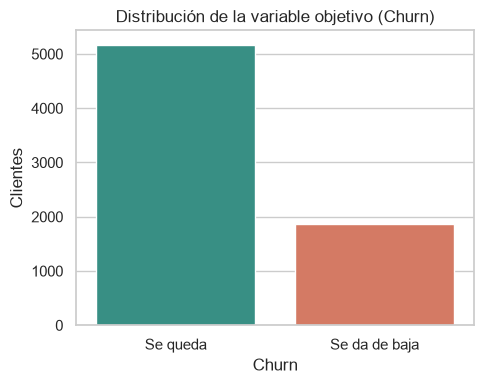

In [11]:
conteo = df["Churn"].value_counts().rename({0: "Se queda", 1: "Se da de baja"})
print(conteo, "\n", (conteo / len(df) * 100).round(1))

fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=conteo.index, y=conteo.values, hue=conteo.index, palette=["#2a9d8f", "#e76f51"], legend=False, ax=ax)
ax.set_title("Distribución de la variable objetivo (Churn)")
ax.set_ylabel("Clientes")
fig.tight_layout()
fig.savefig(GRAFICAS / "01_balance_churn.png", dpi=150)

3. tasa de churn por variable categórica


Contract
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8

InternetService
InternetService
Fiber optic    41.9
DSL            19.0
No              7.4

PaymentMethod
PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2

TechSupport
TechSupport
No     31.2
Yes    15.2

PaperlessBilling
PaperlessBilling
Yes    33.6
No     16.3

SeniorCitizen
SeniorCitizen
Yes    41.7
No     23.6


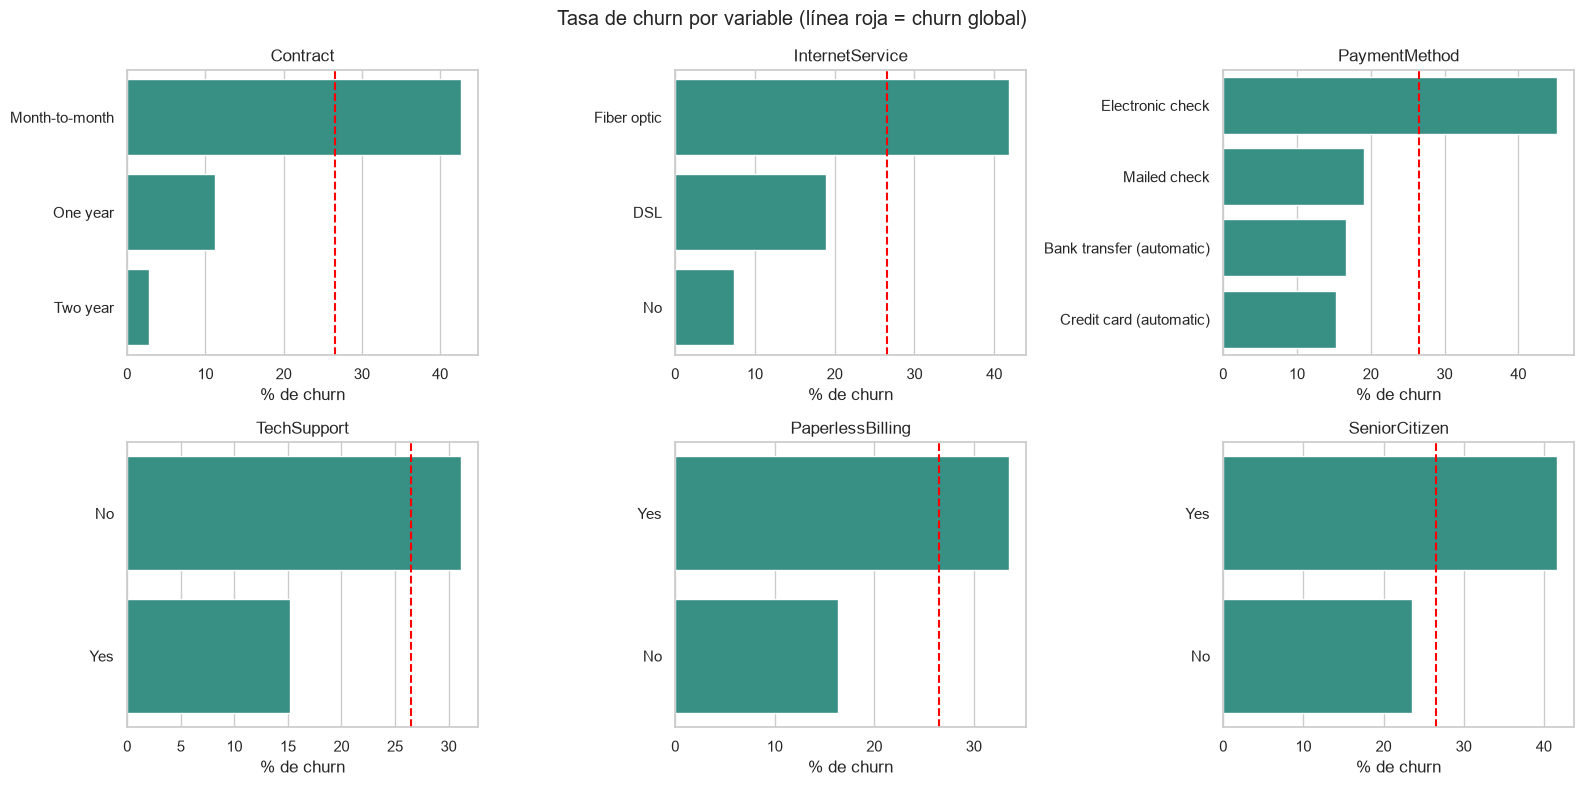

In [12]:
def tasa_churn(col, ax):
    t = df.groupby(col)["Churn"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=t.values, y=t.index, color="#2a9d8f", ax=ax)
    ax.axvline(df["Churn"].mean() * 100, ls="--", c="red")
    ax.set_xlabel("% de churn")
    ax.set_ylabel("")
    ax.set_title(col)
    print(f"\n{col}\n{t.round(1).to_string()}")

cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "PaperlessBilling", "SeniorCitizen"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for c, ax in zip(cols, axes.ravel()):
    tasa_churn(c, ax)
fig.suptitle("Tasa de churn por variable (línea roja = churn global)")
fig.tight_layout()
fig.savefig(GRAFICAS / "02_churn_por_categoria.png", dpi=150)

4. Variables numéricas

       tenure  MonthlyCharges  TotalCharges
Churn                                      
0        38.0            64.4        1679.5
1        10.0            79.6         703.6


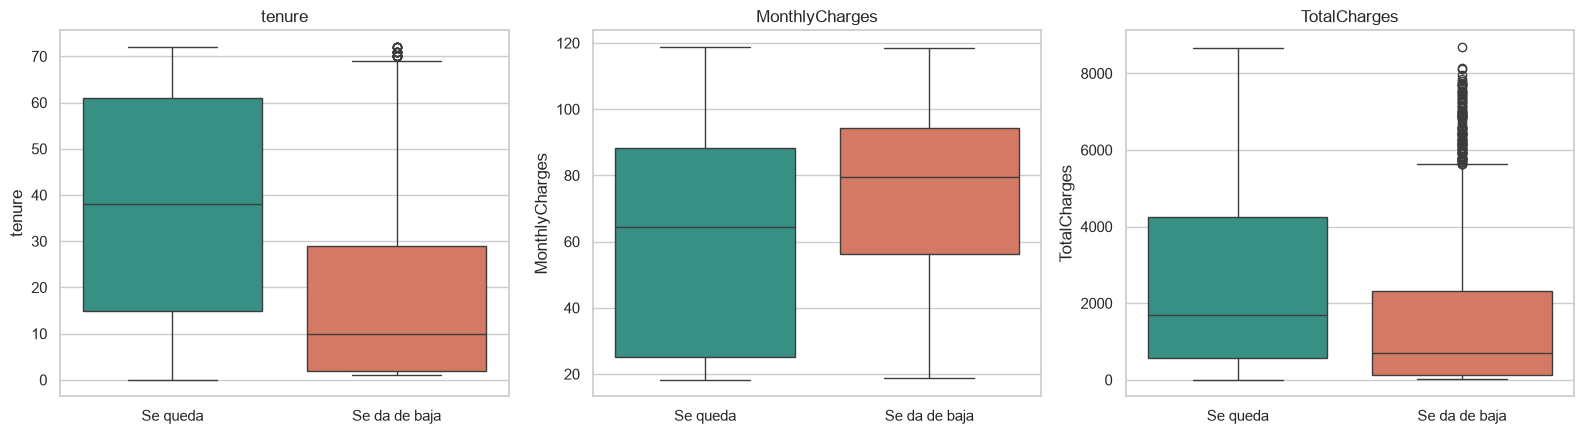

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for c, ax in zip(["tenure", "MonthlyCharges", "TotalCharges"], axes):
    sns.boxplot(data=df, x="Churn", y=c, hue="Churn", palette=["#2a9d8f", "#e76f51"], legend=False, ax=ax)
    ax.set_xticks([0, 1], ["Se queda", "Se da de baja"])
    ax.set_xlabel("")
    ax.set_title(c)
fig.tight_layout()
fig.savefig(GRAFICAS / "03_numericas_vs_churn.png", dpi=150)
print(df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].median().round(1))

5. Correlaciones

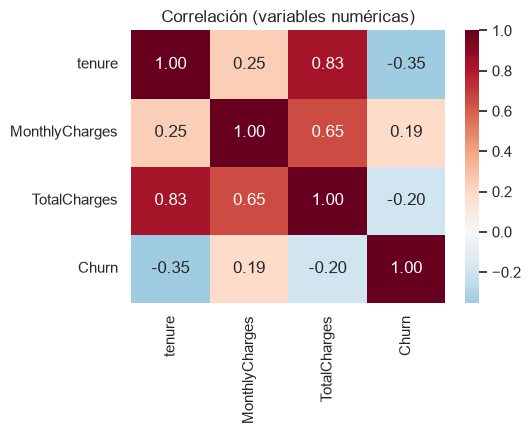

In [14]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(df[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Correlación (variables numéricas)")
fig.tight_layout()
fig.savefig(GRAFICAS / "04_correlacion.png", dpi=150)

6. Anomalías

In [15]:
for c in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1, q3 = df[c].quantile([.25, .75])
    iqr = q3 - q1
    n = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    print(f"{c}: {n} valores atípicos (regla IQR)")

print("Clientes con tenure = 0:", (df["tenure"] == 0).sum())

# Consistencia: TotalCharges debería acercarse a tenure * MonthlyCharges
esperado = df["tenure"] * df["MonthlyCharges"]
desv = ((esperado - df["TotalCharges"]).abs() / df["TotalCharges"].where(df["TotalCharges"] > 0))
print("Desviación relativa TotalCharges vs tenure*MonthlyCharges")
print(desv.describe().round(3))
print("Clientes con desviación > 50%:", (desv > 0.5).sum())

tenure: 0 valores atípicos (regla IQR)
MonthlyCharges: 0 valores atípicos (regla IQR)
TotalCharges: 0 valores atípicos (regla IQR)
Clientes con tenure = 0: 11
Desviación relativa TotalCharges vs tenure*MonthlyCharges
count    7032.000
mean        0.032
std         0.040
min         0.000
25%         0.007
50%         0.020
75%         0.042
max         0.451
dtype: float64
Clientes con desviación > 50%: 0


7. Pruebas estadísticas

In [16]:
from scipy import stats

EVID = RAIZ / "evidencias"
lr = pd.read_csv(EVID / "cv_scores_logistic_regression.csv")["roc_auc"].to_numpy()
rf = pd.read_csv(EVID / "cv_scores_random_forest.csv")["roc_auc"].to_numpy()
d = rf - lr          # diferencia por fold (random forest - regresión logística)
k = len(d)

print(f"AUC CV regresión logística: {lr.mean():.4f} ± {lr.std(ddof=1):.4f}")
print(f"AUC CV random forest:       {rf.mean():.4f} ± {rf.std(ddof=1):.4f}")
print(f"Diferencia media (RF - LR): {d.mean():+.4f}")

t, p_t = stats.ttest_rel(rf, lr)
w, p_w = stats.wilcoxon(rf, lr)
# Corrección de Nadeau y Bengio: 5-fold -> proporción prueba/entrenamiento = 0.25
t_nb = d.mean() / np.sqrt((1 / k + 0.25) * d.var(ddof=1))
p_nb = 2 * stats.t.sf(abs(t_nb), df=k - 1)

resultados_stats = pd.DataFrame({
    "prueba": ["t pareada", "Wilcoxon", "t pareada corregida (Nadeau-Bengio)"],
    "estadístico": [t, w, t_nb],
    "p_value": [p_t, p_w, p_nb],
})
resultados_stats["¿significativa (p<0.05)?"] = resultados_stats["p_value"] < 0.05
resultados_stats.round(4)

AUC CV regresión logística: 0.8464 ± 0.0120
AUC CV random forest:       0.8471 ± 0.0119
Diferencia media (RF - LR): +0.0007


,prueba,estadístico,p_value,¿significativa (p<0.05)?
0,t pareada,0.6869,0.5034,False
1,Wilcoxon,51.0000,0.6387,False
2,t pareada corregida (Nadeau-Bengio),0.3152,0.7573,False


8. Tabla y gráficas comparativas

modelo,logistic_regression,random_forest
test_accuracy,0.8062,0.7913
test_precision,0.6593,0.6739
test_recall,0.5588,0.4144
test_f1,0.6049,0.5132
test_roc_auc,0.8415,0.8429
test_precision_at_15,0.7123,0.6745
test_recall_at_15,0.4037,0.3824


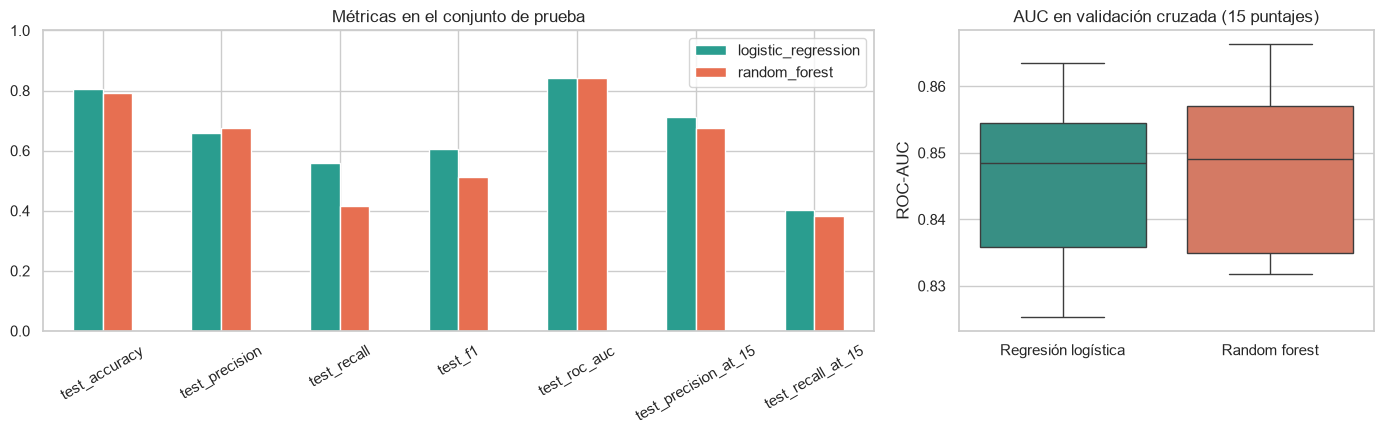

In [17]:
res = pd.read_csv(EVID / "resultados_modelos.csv")
cols = ["test_accuracy", "test_precision", "test_recall", "test_f1",
        "test_roc_auc", "test_precision_at_15", "test_recall_at_15"]
tabla = res.set_index("modelo")[cols].T.round(4)
tabla.to_csv(EVID / "tabla_comparativa.csv")
display(tabla)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
tabla.plot.bar(ax=axes[0], color=["#2a9d8f", "#e76f51"], rot=30)
axes[0].set_title("Métricas en el conjunto de prueba")
axes[0].set_ylim(0, 1)
axes[0].legend(title="")

sns.boxplot(data=pd.DataFrame({"Regresión logística": lr, "Random forest": rf}),
            palette=["#2a9d8f", "#e76f51"], ax=axes[1])
axes[1].set_title("AUC en validación cruzada (15 puntajes)")
axes[1].set_ylabel("ROC-AUC")
fig.tight_layout()
fig.savefig(GRAFICAS / "05_comparacion_modelos.png", dpi=150)

9. Registrar la comparación en MLflow

In [9]:
import mlflow
mlflow.set_tracking_uri(f"sqlite:///{(RAIZ / 'mlflow.db').as_posix()}")
mlflow.set_experiment("Churn_Telco_Sierra_Movil")

with mlflow.start_run(run_name="comparacion_estadistica"):
    mlflow.log_metrics({"p_t_pareada": p_t, "p_wilcoxon": p_w,
                        "p_t_corregida": p_nb, "dif_media_auc_rf_menos_lr": d.mean()})
    mlflow.log_table(resultados_stats, "pruebas_estadisticas.json")
    mlflow.log_artifact(str(EVID / "tabla_comparativa.csv"))
    mlflow.log_artifact(str(GRAFICAS / "05_comparacion_modelos.png"))